# Etapa 3 · Investigação dos dados e consultas SQL

Daniel Suzuki Naves (RA 2363062), João Pedro Novais Zanusso (RA 2607743) e Kalil Nege (RA 2409020) · UTFPR

**Pergunta principal:** depois da privatização da Copel (agosto de 2023), as interrupções de energia não programadas no Paraná aumentaram, diminuíram ou ficaram iguais?

Também olhamos se a Copel passou a sofrer mais com chuva e vento forte (H3 e H4) e, de forma resumida, as hipóteses de carga (H1 e H2), que serão usadas na previsão da Etapa 4.

As consultas SQL rodam no DuckDB direto sobre os Parquets da Etapa 2. O código fica em `src/`:

- `banco.py`: conexão e visões;
- `consultas.py`: as consultas SQL;
- `testes.py`: testes estatísticos;
- `graficos.py`: gráficos.

Cada consulta é impressa antes do resultado.

**Períodos comparados:**

| Período | Datas | Observação |
|---|---|---|
| 1 antes | jan/2022 – jul/2023 | 19 meses |
| 2 depois | ago/2023 – dez/2025 | mesmo esquema de dados da ANEEL; junho/2025 sem dados |
| 3 em 2026 | jan – set/2026 | a ANEEL mudou campos e identificadores; analisado à parte |

A comparação principal é **1 × 2**, porque usa o mesmo formato de dados.

In [1]:
import sys
from pathlib import Path

from IPython.display import display

raiz = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/config.py").is_file())
sys.path.insert(0, str(raiz))

from src import banco, consultas, graficos, testes

con = banco.conectar()
banco.tamanhos(con)

{'base': 1781,
 'carga_d1': 1781,
 'conjunto_dia': 254955,
 'micro': 3186933,
 'dia_np': 1704,
 'dia_carga': 1780}

## 1. Visão geral

### Consulta 1 · Interrupções por mês

Pergunta: Como as interrupções não programadas evoluíram mês a mês?

WITH meses AS (
    SELECT DATE_TRUNC('month', data) AS mes,
           COUNT(*) AS dias_no_mes,
           COUNT(*) FILTER (WHERE NOT sem_registro_interrupcao) AS dias_com_dados
    FROM base
    WHERE data <= (SELECT MAX(data) FROM dia_np)
    GROUP BY 1
),
np AS (
    SELECT DATE_TRUNC('month', data) AS mes,
           AVG(interrupcoes) AS interrupcoes_dia,
           AVG(uc_afetadas) AS uc_afetadas_dia,
           AVG(uc_horas) AS uc_horas_dia,
           MEDIAN(duracao_mediana_h) AS duracao_mediana_h
    FROM dia_np
    GROUP BY 1
)
SELECT m.mes,
       periodo_de(m.mes) AS periodo,
       m.dias_com_dados,
       m.dias_no_mes,
       n.* EXCLUDE (mes),
       -- média móvel de 12 meses: tira a sazonalidade e mostra a tendência
       AVG(n.interrupcoes_dia) OVER (ORDER BY m.mes ROWS BETWEEN 11 PRECEDING AND CURRENT ROW) AS media_movel_12m
FROM meses m
LEFT JOIN np n USING (mes)
ORDER BY m.mes



,mes,periodo,dias_com_dados,dias_no_mes,interrupcoes_dia,uc_afetadas_dia,uc_horas_dia,duracao_mediana_h,media_movel_12m
0,2022-01-01,1 antes,31,31,1699.55,398337.00,188287.14,1.71,1699.55
1,2022-02-01,1 antes,28,28,1420.04,333596.14,156719.32,1.69,1559.79
2,2022-03-01,1 antes,31,31,1820.58,394364.77,238538.49,1.88,1646.72
3,2022-04-01,1 antes,30,30,1616.47,328289.03,460833.68,1.91,1639.16
4,2022-05-01,1 antes,31,31,1144.90,207977.19,102912.17,1.77,1540.31
5,2022-06-01,1 antes,30,30,1066.87,181826.90,82422.87,1.79,1461.40
6,2022-07-01,1 antes,31,31,978.48,183889.61,76906.72,1.67,1392.41
7,2022-08-01,1 antes,31,31,1249.42,224781.52,117897.52,1.72,1374.54
8,2022-09-01,1 antes,30,30,1502.47,263194.07,117402.55,1.75,1388.75
9,2022-10-01,1 antes,31,31,2319.10,451754.97,502362.12,1.87,1481.79


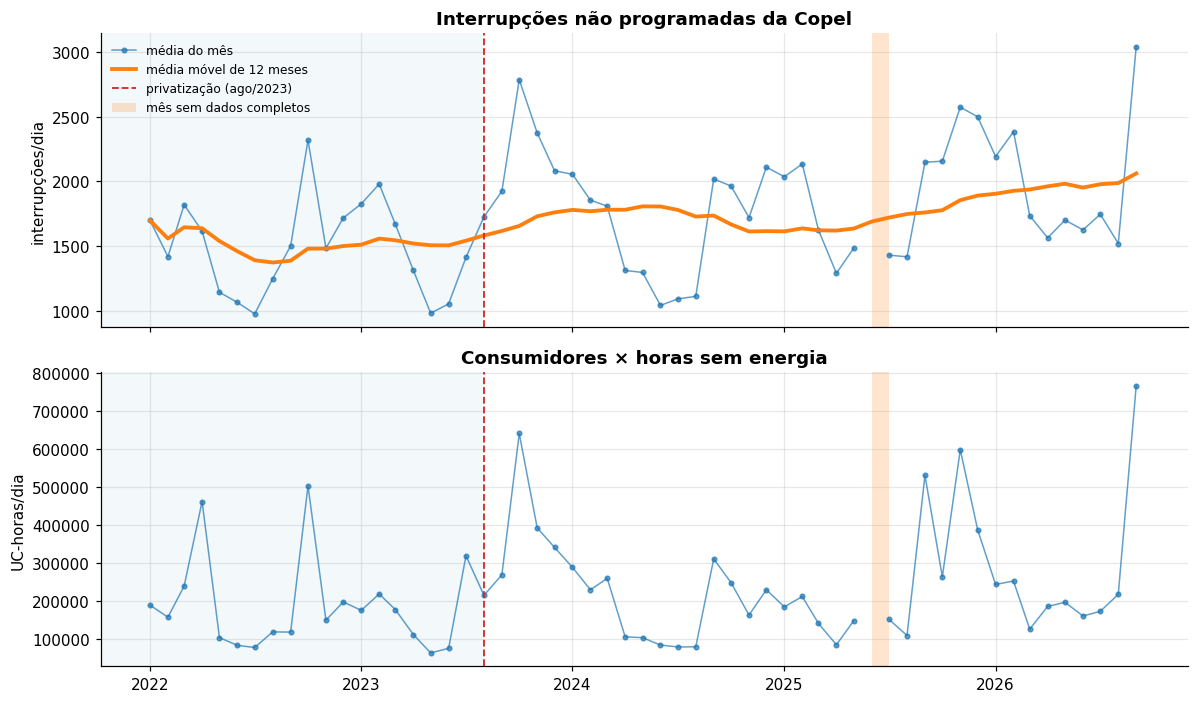

In [2]:
mensal = consultas.rodar(con, "mensal")
display(mensal.round(2))
graficos.interrupcoes_mensais(mensal)

**📝 Interpretação:** _A média móvel de 12 meses sobe, desce ou fica estável depois da linha vermelha? Quais meses têm mais interrupções (verão, temporais)? Junho/2025 está vazio por falta de dados, não por ausência de falhas._

## 2. Antes × depois da privatização

### Consulta 2 · Médias por período

Comparação direta das médias diárias. Ela ainda não controla estação nem clima: o período "antes" tem mais meses de janeiro a julho, por exemplo.

In [3]:
por_periodo = consultas.rodar(con, "por_periodo")
por_periodo.round(3)

Pergunta: Em média, quantas interrupções por dia antes e depois da privatização?

WITH resumo AS (
    SELECT periodo,
           MIN(data) AS inicio,
           MAX(data) AS fim,
           COUNT(*) AS dias,
           AVG(interrupcoes) AS interrupcoes_dia,
           AVG(conjuntos_afetados) AS conjuntos_afetados_dia,
           AVG(uc_afetadas) AS uc_afetadas_dia,
           AVG(uc_horas) AS uc_horas_dia,
           MEDIAN(duracao_mediana_h) AS duracao_mediana_h,
           AVG(chuva_max) AS chuva_max_media
    FROM dia_np
    GROUP BY periodo
)
SELECT *,
       -- variação em relação ao período antes da privatização (primeira linha)
       interrupcoes_dia / FIRST_VALUE(interrupcoes_dia) OVER (ORDER BY periodo) - 1 AS var_interrupcoes,
       uc_horas_dia / FIRST_VALUE(uc_horas_dia) OVER (ORDER BY periodo) - 1 AS var_uc_horas
FROM resumo
ORDER BY periodo



,periodo,inicio,fim,dias,interrupcoes_dia,conjuntos_afetados_dia,uc_afetadas_dia,uc_horas_dia,duracao_mediana_h,chuva_max_media,var_interrupcoes,var_uc_horas
0,1 antes,2022-01-01,2023-07-31,577,1486.995,147.208,296361.863,185707.837,1.717,8.440,0.000,0.000
1,2 depois,2023-08-01,2025-12-31,854,1823.681,149.484,355792.451,243566.419,1.742,7.966,0.226,0.312
2,3 em 2026 (esquema novo),2026-01-01,2026-09-30,273,1939.821,149.941,181730.465,255993.145,2.650,9.891,0.305,0.378


**📝 Interpretação:** _Quanto variaram as interrupções por dia e as UC-horas (consumidores × horas sem energia) entre os períodos? A chuva média foi parecida nos dois períodos?_

### Consulta 3 · Mesmo mês do ano

Para não comparar verão com inverno, comparamos cada mês com ele mesmo (janeiro antes × janeiro depois e assim por diante). O teste de Wilcoxon verifica se, nos 12 meses, a diferença vai sistematicamente para um lado.

Pergunta: Comparando o mesmo mês do ano, depois da privatização há mais interrupções?

WITH por_mes AS (
    SELECT mes,
           COUNT(*) FILTER (WHERE periodo = '1 antes') AS dias_antes,
           COUNT(*) FILTER (WHERE periodo = '2 depois') AS dias_depois,
           AVG(interrupcoes) FILTER (WHERE periodo = '1 antes') AS antes,
           AVG(interrupcoes) FILTER (WHERE periodo = '2 depois') AS depois,
           AVG(chuva_max) FILTER (WHERE periodo = '1 antes') AS chuva_antes,
           AVG(chuva_max) FILTER (WHERE periodo = '2 depois') AS chuva_depois
    FROM dia_np
    GROUP BY mes
)
SELECT *, depois / antes - 1 AS variacao
FROM por_mes
ORDER BY mes



,mes,dias_antes,dias_depois,antes,depois,chuva_antes,chuva_depois,variacao
0,1,62,62,1763.419,2045.597,12.673,11.076,0.160
1,2,56,57,1699.875,1992.860,10.998,10.882,0.172
2,3,62,62,1744.790,1717.194,10.671,5.661,-0.016
3,4,60,60,1465.317,1302.467,8.155,8.703,-0.111
4,5,62,62,1064.355,1392.145,4.510,5.350,0.308
5,6,60,30,1061.300,1043.867,5.957,1.067,-0.016
6,7,62,62,1196.581,1262.726,2.224,4.560,0.055
7,8,31,93,1249.419,1419.710,8.874,4.045,0.136
8,9,30,90,1502.467,2030.800,12.483,5.221,0.352
9,10,31,93,2319.097,2302.280,13.948,12.540,-0.007


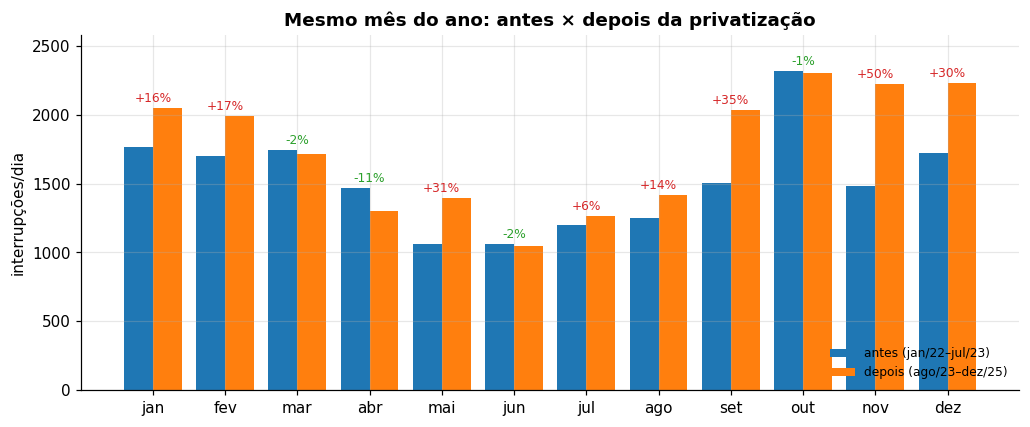

meses                      12.000000
variação mediana            0.148095
meses com aumento           8.000000
p (Wilcoxon, bilateral)     0.026855
Name: mesmo mês: depois × antes, dtype: float64

In [4]:
mesmo_mes = consultas.rodar(con, "mesmo_mes")
display(mesmo_mes.round(3))
graficos.antes_depois_por_mes(mesmo_mes)
testes.teste_mesmo_mes(mesmo_mes)

**📝 Interpretação:** _Em quantos meses houve aumento? O p-valor indica uma mudança sistemática? Algum mês muito chuvoso puxa a diferença?_

### Consulta 4 · DEC e FEC aproximados

A ANEEL avalia as distribuidoras pelo **DEC** (horas sem energia por consumidor) e pelo **FEC** (número de interrupções por consumidor), acumulados em 12 meses. Calculamos versões aproximadas a partir dos microdados:

- **DEC aproximado:** soma de (consumidores afetados × duração) ÷ total de consumidores;
- **FEC aproximado:** soma de consumidores afetados ÷ total de consumidores.

Usamos só as interrupções não programadas. Não são os valores oficiais: não há expurgos, e um consumidor pode aparecer em mais de um registro. Servem para comparar a tendência. Janelas que incluem junho/2025, mês sem dados, ficam de fora.

Pergunta: Indicadores parecidos com DEC e FEC, acumulados em 12 meses (2022–2025)

WITH consumidores AS (
    -- consumidores de cada conjunto no mês (maior valor informado nos registros)
    SELECT DATE_TRUNC('month', data) AS mes, conjunto, MAX(consumidores_conjunto) AS consumidores
    FROM micro
    WHERE data < DATE '2026-01-01'
    GROUP BY ALL
),
total AS (
    SELECT mes, SUM(consumidores) AS consumidores FROM consumidores GROUP BY mes
),
np AS (
    SELECT DATE_TRUNC('month', data) AS mes,
           SUM(uc_horas) AS uc_horas,
           SUM(uc_eventos) AS uc_eventos
    FROM micro
    WHERE nao_programada AND data < DATE '2026-01-01'
    GROUP BY mes
),
mensal AS (
    SELECT n.mes,
           n.uc_horas / t.consumidores AS dec_mes,     -- horas sem energia por consumidor
           n.uc_eventos / t.consumidores AS fec_mes    -- interrupções por consumidor
    FROM np n
    JOIN total t USING (mes)
)
SELECT mes,
       periodo_de(mes) AS periodo,
       dec_mes,
       fec_me

,mes,periodo,dec_mes,fec_mes,meses_na_janela,dec_12m,fec_12m
32,2024-09-01,2 depois,1.807,2.262,12,17.400,24.662
33,2024-10-01,2 depois,1.487,2.133,12,14.975,23.517
34,2024-11-01,2 depois,0.942,1.922,12,13.605,22.646
35,2024-12-01,2 depois,1.371,2.282,12,12.903,22.356
36,2025-01-01,2 depois,1.099,2.453,12,12.252,22.203
37,2025-02-01,2 depois,1.140,2.386,12,12.090,22.280
38,2025-03-01,2 depois,0.837,1.785,12,11.356,21.608
39,2025-04-01,2 depois,0.485,1.295,12,11.225,21.456
40,2025-05-01,2 depois,0.876,1.663,12,11.479,21.693
41,2025-07-01,2 depois,0.894,1.543,11,NaN,NaN


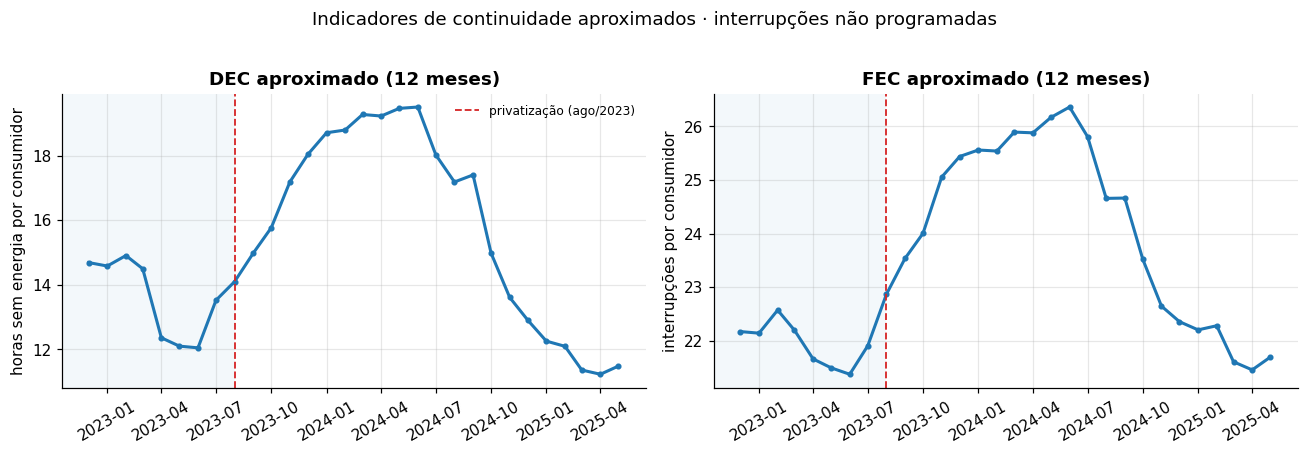

In [5]:
indicadores = consultas.rodar(con, "dec_fec")
completos = indicadores.meses_na_janela.eq(12)
indicadores.loc[~completos, ["dec_12m", "fec_12m"]] = None
display(indicadores.round(3).tail(15))
graficos.dec_fec(indicadores)

**📝 Interpretação:** _O DEC e o FEC acumulados sobem ou descem depois de ago/2023? Compare o último valor disponível com o valor de jul/2023._

### Teste principal · A privatização mudou o número de interrupções?

Ajustamos uma regressão de contagem (binomial negativa, adequada a contagens com muita variação) com as interrupções do dia e o indicador **depois** (1 a partir de ago/2023). Como controles, entram mês, dia da semana, feriado, chuva e rajada do dia. Assim, uma diferença explicada só por estação ou por um período mais chuvoso não é atribuída à privatização.

A **razão** é o efeito de "depois": 1,10 significa 10% a mais de interrupções esperadas e 0,95 significa 5% a menos. Os erros-padrão consideram que dias vizinhos são parecidos (HAC).

**Como ler "não houve diferença".** Um p-valor alto sozinho não prova que não houve mudança; pode ser só falta de dados. Por isso, só concluímos "sem diferença relevante" quando o **intervalo de confiança inteiro** fica entre 0,90 e 1,10, ou seja, quando os dados descartam mudanças maiores que 10%. A margem de 10% é uma escolha nossa.

O modelo "com tendência" separa um salto em ago/2023 de uma tendência que já vinha de antes. Com só 19 meses no período anterior, esse modelo é menos preciso.

,razão,IC95% inf,IC95% sup,p,leitura
interrupções/dia · 2022–2025,1.149,1.091,1.209,0.000,aumento
interrupções/dia · com 2026 (controle do esquema),1.152,1.093,1.214,0.000,aumento
UC-horas/dia · 2022–2025,1.131,1.026,1.247,0.013,aumento
conjuntos afetados/dia · 2022–2025,1.014,1.010,1.017,0.000,aumento pequeno (IC dentro de ±10%)
salto em ago/2023 (com tendência),1.035,0.931,1.150,0.526,inconclusivo (IC largo)
mudança de tendência por ano,0.945,0.856,1.043,0.263,inconclusivo (IC largo)


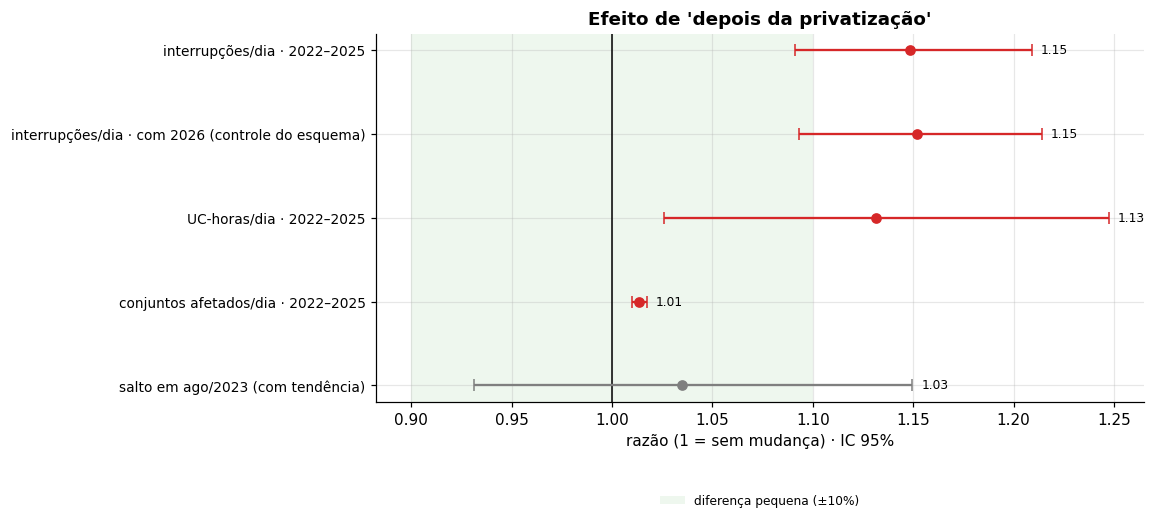

In [6]:
dias = testes.preparar_dias(con.sql("SELECT * FROM dia_np").df())
privatizacao = testes.teste_privatizacao(dias)
display(privatizacao.round(3))
graficos.razoes(privatizacao.drop(index="mudança de tendência por ano"), "Efeito de 'depois da privatização'")

**📝 Interpretação:** _A razão de 'depois' é maior, menor ou igual a 1? O IC cabe dentro de ±10%? O resultado se mantém com 2026, em UC-horas, em conjuntos afetados e no modelo com tendência? Esta é a resposta principal do trabalho._

### Consulta 5 · Causas

Separamos a causa informada pela ANEEL no campo de fato gerador, por exemplo "PROPRIAS DO SISTEMA", "TERCEIROS" e "MEIO AMBIENTE". Usamos só 2022–2025, porque em 2026 o texto desse campo mudou de formato.

Pergunta: As causas das interrupções mudaram depois da privatização? (2022–2025)

WITH registros AS (
    SELECT periodo_de(data) AS periodo,
           COALESCE(NULLIF(TRIM(regexp_extract(UPPER(fato_gerador), 'PROGRAMADA-([^-]+)', 1)), ''),
                    'NAO INFORMADA') AS causa
    FROM micro
    WHERE nao_programada AND esquema_aneel = 'ate2025'
),
contagem AS (
    SELECT periodo, causa, COUNT(*) AS registros FROM registros GROUP BY ALL
),
dias AS (
    SELECT periodo, COUNT(*) AS dias FROM dia_np GROUP BY periodo
)
SELECT c.periodo,
       c.causa,
       c.registros,
       c.registros / d.dias AS registros_por_dia,
       c.registros / SUM(c.registros) OVER (PARTITION BY c.periodo) AS participacao
FROM contagem c
JOIN dias d USING (periodo)
ORDER BY c.causa, c.periodo



periodo,1 antes,2 depois
causa,,
ALIVIO DE CARGA,NaN,1.5
ALTERACAO,NaN,0.0
FALHA OPERACIONAL,2.3,2.7
MANUTENCAO,NaN,0.0
MEIO AMBIENTE,685.5,851.3
NAO CLASSIFICADA,1.6,2.0
NAO INFORMADA,0.2,NaN
PROPRIAS DO SISTEMA,717.0,873.9
TERCEIRO,NaN,0.0


periodo,1 antes,2 depois
causa,,
ALIVIO DE CARGA,NaN,0.1
ALTERACAO,NaN,0.0
FALHA OPERACIONAL,0.2,0.1
MANUTENCAO,NaN,0.0
MEIO AMBIENTE,46.1,46.7
NAO CLASSIFICADA,0.1,0.1
NAO INFORMADA,0.0,NaN
PROPRIAS DO SISTEMA,48.2,47.9
TERCEIRO,NaN,0.0


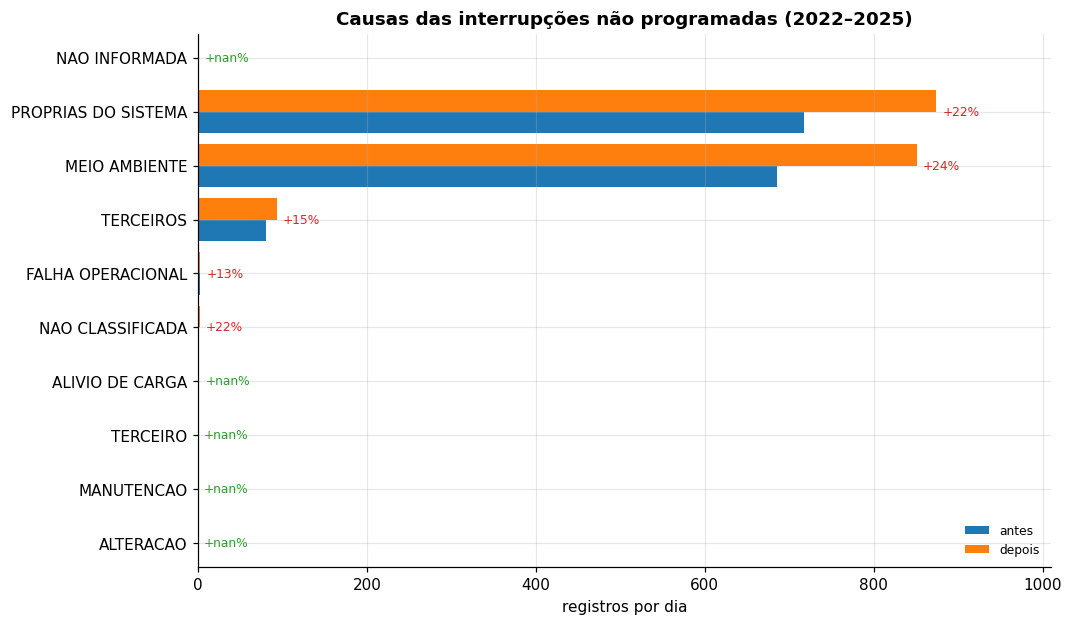

In [7]:
causas = consultas.rodar(con, "causas")
por_dia = causas.pivot(index="causa", columns="periodo", values="registros_por_dia")
participacao = causas.pivot(index="causa", columns="periodo", values="participacao")
display(por_dia.round(1))
display((participacao * 100).round(1))
graficos.causas(por_dia.sort_values("2 depois").tail(10))  # 10 causas mais frequentes

**📝 Interpretação:** _Alguma causa cresceu mais que as outras depois da privatização? Um aumento em falhas 'próprias do sistema' poderia indicar manutenção, e um aumento em 'meio ambiente', clima ou vegetação._

### Consulta 6 · Duração

Além do número de interrupções, importa quanto tempo se leva para religar. Eventos acima de 7 dias, marcados na Etapa 2 como suspeitos, ficam de fora. O teste de Mann-Whitney compara as distribuições, e o resultado é a chance de uma interrupção do período "depois" durar mais que uma do "antes" (0,5 = iguais).

Pergunta: As interrupções passaram a durar mais depois da privatização?

SELECT periodo_de(data) AS periodo,
       COUNT(*) AS registros,
       AVG(duracao_h) AS media_h,
       MEDIAN(duracao_h) AS mediana_h,
       quantile_cont(duracao_h, 0.9) AS p90_h,
       AVG(CAST(duracao_h > 3 AS DOUBLE)) AS frac_mais_3h,
       AVG(CAST(duracao_h > 24 AS DOUBLE)) AS frac_mais_24h
FROM micro
WHERE nao_programada AND NOT duracao_suspeita AND duracao_h IS NOT NULL
GROUP BY 1
ORDER BY 1



,periodo,registros,media_h,mediana_h,p90_h,frac_mais_3h,frac_mais_24h
0,1 antes,858239,3.867,1.833,8.683,0.324,0.024
1,2 depois,1557894,4.300,1.883,10.917,0.349,0.030
2,3 em 2026 (esquema novo),529030,5.567,2.667,14.833,0.459,0.040


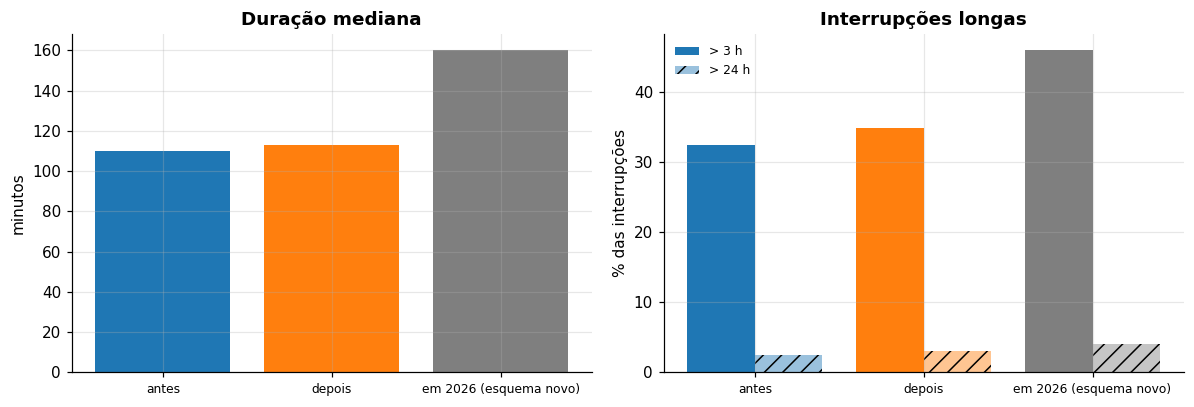

P(depois dura mais que antes)    0.507628
p (Mann-Whitney)                 0.117881
Name: duração: depois × antes, dtype: float64

In [8]:
duracao = consultas.rodar(con, "duracao")
display(duracao.round(3))
graficos.duracao(duracao)
testes.teste_duracao(con)

**📝 Interpretação:** _A mediana e a fração de interrupções longas (> 3 h, > 24 h) mudaram? Com tantos registros, até diferenças minúsculas dão p pequeno, então olhe também o tamanho da diferença._

## 3. Clima e privatização (H3 e H4)

### Consulta 7 · Dias de chuva ou vento extremos

Um dia é **extremo** quando a maior chuva ou a maior rajada entre as cinco cidades passa do percentil 95. A razão mostra quantas vezes mais interrupções ocorrem num dia extremo do que num dia normal, em cada período.

O modelo testa se essa razão mudou depois de ago/2023 (interação extremo × depois), controlando mês, dia da semana, feriado e tendência.

Pergunta: Em dias de chuva ou vento forte, a Copel passou a ter mais ou menos interrupções?

WITH limiares AS (
    -- dia extremo: chuva ou rajada acima do percentil 95 do período todo
    SELECT quantile_cont(chuva_max, 0.95) AS p95_chuva,
           quantile_cont(rajada_max, 0.95) AS p95_rajada
    FROM dia_np
    WHERE chuva_max IS NOT NULL
),
dias AS (
    SELECT d.*, (d.chuva_max >= l.p95_chuva OR d.rajada_max >= l.p95_rajada) AS extremo
    FROM dia_np d, limiares l
    WHERE d.chuva_max IS NOT NULL
)
SELECT periodo,
       COUNT(*) FILTER (WHERE extremo) AS dias_extremos,
       COUNT(*) FILTER (WHERE NOT extremo) AS dias_normais,
       AVG(interrupcoes) FILTER (WHERE extremo) AS media_dia_extremo,
       AVG(interrupcoes) FILTER (WHERE NOT extremo) AS media_dia_normal,
       media_dia_extremo / media_dia_normal AS razao
FROM dias
GROUP BY periodo
ORDER BY periodo



,periodo,dias_extremos,dias_normais,media_dia_extremo,media_dia_normal,razao
0,1 antes,45,532,2804.02,1375.59,2.04
1,2 depois,74,780,3610.30,1654.18,2.18
2,3 em 2026 (esquema novo),37,236,3174.86,1746.19,1.82


,razão,IC95% inf,IC95% sup,p
dia extremo · antes,2.088,1.787,2.441,0.000
dia extremo · depois,2.082,1.856,2.335,0.000
mudança (depois ÷ antes),0.997,0.823,1.208,0.975


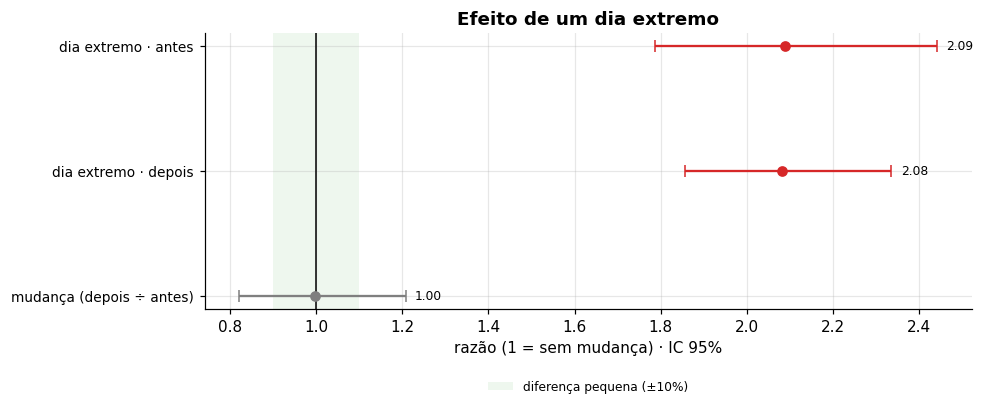

In [9]:
clima = consultas.rodar(con, "clima_periodo")
display(clima.round(2))
clima_teste = testes.teste_clima_periodo(dias)
display(clima_teste.round(3))
graficos.razoes(clima_teste, "Efeito de um dia extremo")

**📝 Interpretação:** _H3: um dia extremo tem mais interrupções (razão > 1)? H4: a rede ficou mais ou menos sensível a temporais depois da privatização? A conclusão é associativa: El Niño 2023–24, investimentos e regulação mudaram ao mesmo tempo._

## 4. Recorrência no mesmo conjunto

### Consulta 8 · Tempo até a próxima falha

Para cada conjunto elétrico, `LAG()` encontra a falha anterior e calcula quantos dias se passaram. Intervalos que atravessam dias sem dados da ANEEL são descartados.

In [10]:
consultas.rodar(con, "recorrencia").round(3)

Pergunta: Quando um conjunto falha, quanto tempo leva para falhar de novo?

WITH cobertura AS (
    -- contador de dias sem dados da ANEEL, para descartar intervalos que atravessam lacunas
    SELECT data, SUM(CAST(sem_registro_interrupcao AS INT)) OVER (ORDER BY data) AS lacunas
    FROM base
),
falhas AS (
    SELECT c.conjunto, c.data, k.lacunas
    FROM conjunto_dia c
    JOIN cobertura k USING (data)
    WHERE c.interrupcoes_nao_programadas > 0
),
intervalos AS (
    SELECT conjunto, data,
           date_diff('day', LAG(data) OVER w, data) AS dias_desde_anterior,
           lacunas - LAG(lacunas) OVER w AS lacunas_no_intervalo
    FROM falhas
    WINDOW w AS (PARTITION BY conjunto ORDER BY data)
)
SELECT periodo_de(data) AS periodo,
       COUNT(*) AS intervalos,
       AVG(CAST(dias_desde_anterior = 1 AS DOUBLE)) AS frac_no_dia_seguinte,
       AVG(CAST(dias_desde_anterior <= 7 AS DOUBLE)) AS frac_em_ate_7_dias,
       MEDIAN(dias_desde_anterior) AS mediana_dias,
       AVG(dias

,periodo,intervalos,frac_no_dia_seguinte,frac_em_ate_7_dias,mediana_dias,media_dias
0,1 antes,84782,0.954,1.000,1.0,1.066
1,2 depois,127502,0.965,1.000,1.0,1.050
2,3 em 2026 (esquema novo),40898,0.968,0.999,1.0,1.050


**📝 Interpretação:** _Depois da privatização, os conjuntos voltam a falhar mais rápido (mais falhas no dia seguinte ou na mesma semana)?_

## 5. Demanda (resumo para a Etapa 4)

### Consulta 9 · Carga × temperatura (H1)

Dias úteis sem feriado. A carga é dividida pela média do ano para o crescimento anual não atrapalhar. H1 espera um formato em "U": carga maior no frio e no calor. O teste confere se o termo T² é positivo e onde fica o mínimo da curva.

Pergunta: A carga máxima do Sul muda com a temperatura? (dias úteis)

WITH uteis AS (
    SELECT temp_media,
           -- carga dividida pela média do ano, para o crescimento anual não atrapalhar
           carga_max / AVG(carga_max) OVER (PARTITION BY YEAR(data)) AS carga_relativa
    FROM dia_carga
    WHERE n_ufs_feriado = 0 AND dia_semana < 5 AND temp_media IS NOT NULL
)
SELECT FLOOR(temp_media / 2) * 2 AS faixa_inicio,
       COUNT(*) AS dias,
       AVG(carga_relativa) AS carga_relativa
FROM uteis
GROUP BY 1
HAVING COUNT(*) >= 10
ORDER BY 1



,faixa_inicio,dias,carga_relativa
0,8.0,10,0.995
1,10.0,28,0.999
2,12.0,50,0.984
3,14.0,120,0.968
4,16.0,157,0.956
5,18.0,205,0.955
6,20.0,260,0.985
7,22.0,275,1.041
8,24.0,114,1.101
9,26.0,12,1.145


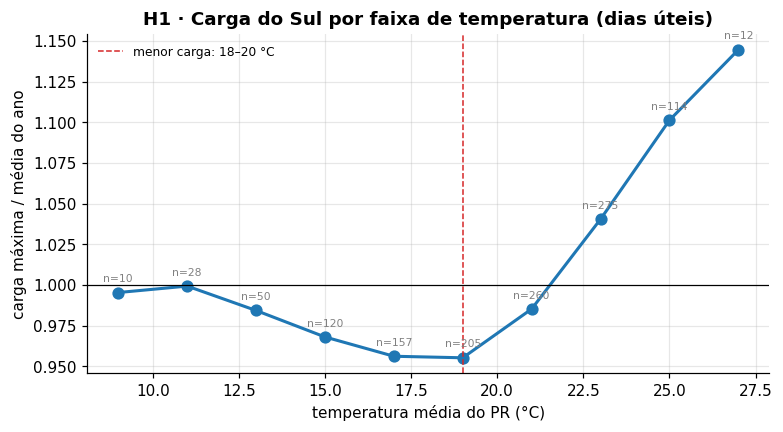

coef. T²                           1.817864e-03
p T²                               2.953141e-29
temperatura de menor carga (°C)    1.601934e+01
Name: H1 · carga × temperatura, dtype: float64

In [11]:
faixas = consultas.rodar(con, "carga_temperatura")
display(faixas.round(3))
graficos.carga_temperatura(faixas)
testes.teste_temperatura(con.sql("SELECT * FROM dia_carga").df())

**📝 Interpretação:** _A curva tem formato de U? A temperatura de menor carga fica perto dos 18–22 °C da proposta?_

### Consulta 10 · Feriados (H2)

Cada feriado em dia útil é comparado com o mesmo dia da semana 7 e 14 dias antes e depois, sem feriado.

In [12]:
feriados = consultas.rodar(con, "feriados")
display(feriados.round(3).head(10))
testes.teste_feriados(feriados)

Pergunta: Quanto a carga cai num feriado em relação aos dias úteis parecidos?

WITH feriados AS (
    SELECT data, carga_max, n_ufs_feriado,
           COALESCE(feriado_nome, 'feriado estadual SC/RS') AS feriado
    FROM dia_carga
    WHERE n_ufs_feriado > 0 AND dia_semana < 5
),
referencias AS (
    -- mesmo dia da semana 7 e 14 dias antes e depois, sem feriado
    SELECT f.data, AVG(r.carga_max) AS carga_referencia, COUNT(*) AS n_referencias
    FROM feriados f
    JOIN dia_carga r ON r.n_ufs_feriado = 0 AND ABS(date_diff('day', f.data, r.data)) IN (7, 14)
    GROUP BY f.data
)
SELECT f.data, f.feriado, f.n_ufs_feriado, f.carga_max, r.carga_referencia,
       f.carga_max / r.carga_referencia - 1 AS variacao
FROM feriados f
JOIN referencias r USING (data)
WHERE r.n_referencias >= 2
ORDER BY variacao



,data,feriado,n_ufs_feriado,carga_max,carga_referencia,variacao
0,2024-01-01,Confraternização Universal,3,13157.185,19254.400,-0.317
1,2026-01-01,Confraternização Universal,3,13707.431,18754.314,-0.269
2,2023-12-25,Natal,3,13403.732,18333.979,-0.269
3,2023-04-07,Sexta-feira Santa,3,12114.641,16206.370,-0.252
4,2025-01-01,Confraternização Universal,3,13423.447,17872.465,-0.249
5,2024-12-25,Natal,3,12686.984,16852.567,-0.247
6,2022-04-15,Sexta-feira Santa,3,11193.887,14177.573,-0.210
7,2024-03-29,Sexta-feira Santa,3,14052.089,17562.995,-0.200
8,2025-12-25,Natal,3,14262.176,17749.769,-0.196
9,2023-11-02,Finados,3,13550.899,16384.448,-0.173


feriados nacionais          3.300000e+01
variação mediana           -1.341409e-01
p (Wilcoxon, unilateral)    2.328306e-10
Name: H2 · feriados nacionais, dtype: float64

**📝 Interpretação:** _Quanto a carga cai num feriado nacional? Isso justifica usar o feriado do dia previsto como atributo na Etapa 4._

## 6. Conclusões

_A completar com os resultados:_

1. **Privatização:** as interrupções aumentaram, diminuíram ou não mudaram de forma relevante? Cite a razão e o IC do teste principal e confira se DEC/FEC, causas e duração apontam na mesma direção.
2. **Clima (H3/H4):** quanto um dia extremo aumenta as interrupções e se isso mudou depois de ago/2023.
3. **Demanda (H1/H2):** formato da curva de temperatura e efeito dos feriados, que entram como atributos na Etapa 4.

**Limitações:**

- É uma comparação antes × depois, sem um grupo de controle. Outras coisas mudaram no mesmo período (El Niño 2023–24, regras da ANEEL, investimentos), então os resultados indicam associação, não causa.
- O período anterior tem só 19 meses, porque os dados começam em 2022.
- Junho/2025 está sem dados, e em 2026 a ANEEL mudou o formato.
- DEC e FEC são aproximados, não os oficiais.
- O clima vem de cinco cidades, que só aproximam toda a área da Copel.